# EDA · physical_lojas 

| Seção | Pergunta |
|---|---|
| 1 | O cadastro está íntegro? (chaves, nomes e CNPJ duplicados, CNPJ inválido) |
| 2 | Os textos estão padronizados? |
| 3 | Como as lojas se distribuem por estado, cidade e peso_vendas? |
| 4 | O cadastro bate com as vendas e o peso_vendas explica a receita? |
| 5 | Resumo dos achados |
| 6 | Conclusões e decisões para a engenharia de features |

## 0. CONFIGURAÇÃO

In [0]:
%pip install python-dotenv --quiet

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import os
import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from pyspark.sql import DataFrame, functions as F, types as T

load_dotenv("/Workspace/Users/eng.stephanni@gmail.com/.env", override=True)

CONTA = os.environ["STORAGE_ACCOUNT_NAME"]
HOST = f"{CONTA}.dfs.core.windows.net"
AUTH = {
    f"fs.azure.account.auth.type.{HOST}": "OAuth",
    f"fs.azure.account.oauth.provider.type.{HOST}": "org.apache.hadoop.fs.azurebfs.oauth2.ClientCredsTokenProvider",
    f"fs.azure.account.oauth2.client.id.{HOST}": os.environ["ADLS_CLIENT_ID"],
    f"fs.azure.account.oauth2.client.secret.{HOST}": os.environ["ADLS_CLIENT_SECRET"],
    f"fs.azure.account.oauth2.client.endpoint.{HOST}": f"https://login.microsoftonline.com/{os.environ['ADLS_TENANT_ID']}/oauth2/token",
}

# Onde está a tabela da Silver (container, caminho) — Delta. Vendas só para cruzar na seção 4.
SILVER = {
    "physical_lojas": ("squad3", "silver/physical_lojas"),
    "physical_vendas_caixa": ("raw", "silver/physical_vendas_caixa"),
}
DESTINO = ("squad3", "ml")   # saída das próximas etapas (nunca a Silver)


def url(container: str, caminho: str) -> str:
    return f"abfss://{container}@{HOST}/{caminho}"


def ler(tabela: str) -> DataFrame:
    """Lê uma tabela da Silver."""
    return spark.read.format("delta").options(**AUTH).load(url(*SILVER[tabela]))


def salvar(df: DataFrame, nome: str, particoes: list = None) -> None:
    """Grava em squad3/ml/<nome> (Delta). Bloqueia qualquer gravação na Silver."""
    if "silver" in nome.lower():
        raise ValueError("A Silver é somente leitura.")
    w = df.write.format("delta").options(**AUTH).mode("overwrite").option("overwriteSchema", "true")
    (w.partitionBy(*particoes) if particoes else w).save(url(DESTINO[0], f"{DESTINO[1]}/{nome}"))


def perfil(df: DataFrame) -> pd.DataFrame:
    """Tipo, nulos e distintos de cada coluna."""
    n = df.count()
    agg = df.agg(*[F.sum(F.col(c).isNull().cast("int")).alias(f"n_{c}") for c in df.columns],
                 *[F.approx_count_distinct(c).alias(f"d_{c}") for c in df.columns]).first()
    return pd.DataFrame({
        "coluna": df.columns,
        "tipo": [f.dataType.simpleString() for f in df.schema],
        "nulos": [agg[f"n_{c}"] for c in df.columns],
        "pct_nulos": [round(100 * agg[f"n_{c}"] / n, 2) for c in df.columns],
        "distintos": [agg[f"d_{c}"] for c in df.columns],
    })


def grafico_barras(df: DataFrame, coluna: str, top: int = 30) -> None:
    """Quantas lojas há em cada valor da coluna (a quantidade aparece na ponta da barra)."""
    p = df.groupBy(coluna).count().orderBy(F.desc("count")).limit(top).toPandas()[::-1]
    fig, ax = plt.subplots(figsize=(8, max(2.5, 0.35 * len(p))))
    barras = ax.barh(p[coluna].astype(str), p["count"], color=AZUL)
    ax.bar_label(barras, padding=3)
    ax.set(title=f"Quantidade de lojas por {coluna}", xlabel="nº de lojas", ylabel=coluna)
    plt.tight_layout(); plt.show()


def cnpj_valido(cnpj) -> bool:
    """Confere os 2 dígitos verificadores do CNPJ."""
    c = "".join(ch for ch in str(cnpj) if ch.isdigit()).zfill(14)
    if len(c) != 14 or len(set(c)) == 1:
        return False
    for n in (12, 13):
        r = sum(int(d) * p for d, p in zip(c, list(range(n - 7, 1, -1)) + list(range(9, 1, -1)))) % 11
        if int(c[n]) != (0 if r < 2 else 11 - r):
            return False
    return True


plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#E6EAEE"})
AZUL, OURO = "#1F4E8C", "#D99A00"

## 1. ESTRUTURA E INTEGRIDADE DO CADASTRO

In [0]:
df = ler("physical_lojas")
n = df.count()
print(f"{n:,} linhas · {len(df.columns)} colunas")
display(perfil(df))
display(df.orderBy("id_loja"))

ids = sorted(r.id_loja for r in df.select("id_loja").distinct().collect())
digitos = F.regexp_replace(F.col("cnpj").cast("string"), "[^0-9]", "")
lojas = df.toPandas()   # tabela pequena: o resto da análise roda em pandas
lojas["peso_vendas"] = pd.to_numeric(lojas.peso_vendas)

checagens = {
    "id_loja duplicado": n - len(ids),
    "ids ausentes na sequência": len(set(range(min(ids), max(ids) + 1)) - set(ids)),
    "nome_loja duplicado": n - df.select("nome_loja").distinct().count(),
    "cnpj duplicado": n - df.select("cnpj").distinct().count(),
    "cnpj com dígito verificador inválido": int((~lojas.cnpj.map(cnpj_valido)).sum()),
    "peso_vendas nulo ou <= 0": df.filter(F.col("peso_vendas").isNull() | (F.col("peso_vendas") <= 0)).count(),
}
display(pd.DataFrame(checagens.items(), columns=["checagem", "linhas"]))
print("ids ausentes:", sorted(set(range(min(ids), max(ids) + 1)) - set(ids)))
print("Quantidade de dígitos do CNPJ (o tipo numérico perde zeros à esquerda):")
display(df.groupBy(F.length(digitos).alias("digitos")).count())

25 linhas · 12 colunas


coluna,tipo,nulos,pct_nulos,distintos
id_loja,int,0,0.0,26
nome_loja,string,0,0.0,24
cnpj,string,0,0.0,25
cidade_loja,string,0,0.0,26
estado_loja,string,0,0.0,4
peso_vendas,int,0,0.0,8
bronze_ingested_at,timestamp,0,0.0,1
bronze_source_file,string,0,0.0,1
ano,int,0,0.0,1
mes,int,0,0.0,1


id_loja,nome_loja,cnpj,cidade_loja,estado_loja,peso_vendas,bronze_ingested_at,bronze_source_file,ano,mes,_hash_registro,silver_processed_at
1,Loja São Bernardo do Campo - Alves Dias,10679285000192,São Bernardo do Campo,SP,7,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,369b0767629109babea63d61c0b078beca70a2cd167fcdbdfd6fe73f552eafb9,2026-10-07T18:40:07.687Z
2,Loja Duque de Caxias - Jardim Primavera,32104758000166,Duque de Caxias,RJ,10,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,76bd4de85267acdb49c1e6710ef8e7128ca4cda32848ff4774e75cc28c363218,2026-10-07T18:40:07.687Z
3,Loja Sertãozinho - Jardim Lopes da Silva,85230196000163,Sertãozinho,SP,8,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,e8aafff6534bac0787091e789d49e622ceb6fed012c267bd35e0ea58e280f226,2026-10-07T18:40:07.687Z
4,Loja Campos dos Goytacazes - nan,24653987000101,Campos dos Goytacazes,RJ,7,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,2c1f8893b287736be0393dd0ebe5d9834355089f9ffb460bdf46e874c7493734,2026-10-07T18:40:07.687Z
5,Loja Barueri - Jardim Tupan,24918563000121,Barueri,SP,9,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,29bd7d97f7a234eedd30a85dad27af04897140d4d3ad28e1c52705cf8918b3a5,2026-10-07T18:40:07.687Z
6,Loja Itapeva - Centro,29305167000142,Itapeva,SP,10,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,e8d8c9ad412b533d7da3b577c5ad2b064eeb5da311094dbe17035a30fd55c974,2026-10-07T18:40:07.687Z
8,Loja Mairiporã - Pirucaia,28146590000184,Mairiporã,SP,7,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,7b7a03fc771ceba0b20f2d794e6a88c9b7cb79e1abeb505a603a6c917303739e,2026-10-07T18:40:07.687Z
9,Loja Belford Roxo - Nova Aurora,45632907000101,Belford Roxo,RJ,10,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,2fc8d9f8d029e7c110d54a9294239067ba1e7aa6dc55c5bd56c92f5ae98747b5,2026-10-07T18:40:07.687Z
10,Loja Itapecerica - nan,56917843000101,Itapecerica,MG,10,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,80df3901be6a2a486a34bb9794dece79e664ae23e6072c74727c716ae17fa6af,2026-10-07T18:40:07.687Z
12,Loja Pontal - Conjunto José Pedro Carolo,23568907000157,Pontal,SP,3,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,53b4a8d12acaa50d56ad2bb2dd88ccc867052131ad2b9ae0def24144acb23a7d,2026-10-07T18:40:07.687Z


checagem,linhas
id_loja duplicado,0
ids ausentes na sequência,5
nome_loja duplicado,0
cnpj duplicado,0
cnpj com dígito verificador inválido,0
peso_vendas nulo ou <= 0,0


ids ausentes: [7, 11, 14, 15, 29]
Quantidade de dígitos do CNPJ (o tipo numérico perde zeros à esquerda):


digitos,count
14,25


## 2. PADRONIZAÇÃO DOS TEXTOS

In [0]:
textos = [f.name for f in df.schema if isinstance(f.dataType, T.StringType)]
problema = lambda c: F.lower(F.col(c)).isin("nan", "null", "none") | (F.trim(F.col(c)) == "") | (F.col(c) != F.trim(F.col(c)))
display(df.select(*[F.sum(problema(c).cast("int")).alias(c) for c in textos]))

# Mesma cidade/estado escrito de jeitos diferentes (maiúsculas, acento, espaço)?
sem_acento = lambda c: F.translate(F.lower(F.trim(F.col(c))), "áàâãéêíóôõúç", "aaaaeeiooouc")
display(pd.DataFrame([{"coluna": c, "distintos": df.select(c).distinct().count(),
                       "distintos_normalizados": df.select(sem_acento(c)).distinct().count()}
                      for c in ["cidade_loja", "estado_loja"]]))

nome_loja,cnpj,cidade_loja,estado_loja,bronze_source_file,_hash_registro
0,0,0,0,0,0


coluna,distintos,distintos_normalizados
cidade_loja,25,25
estado_loja,4,4


## 3. DISTRIBUIÇÃO DAS LOJAS

Total de lojas no cadastro: 25


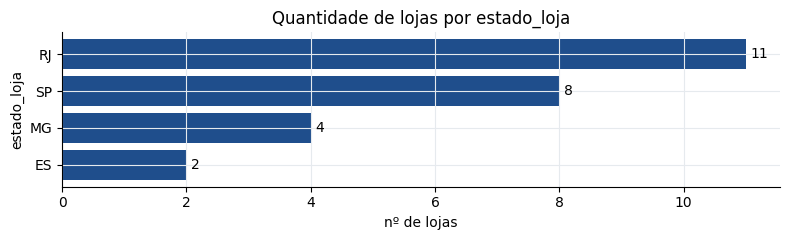

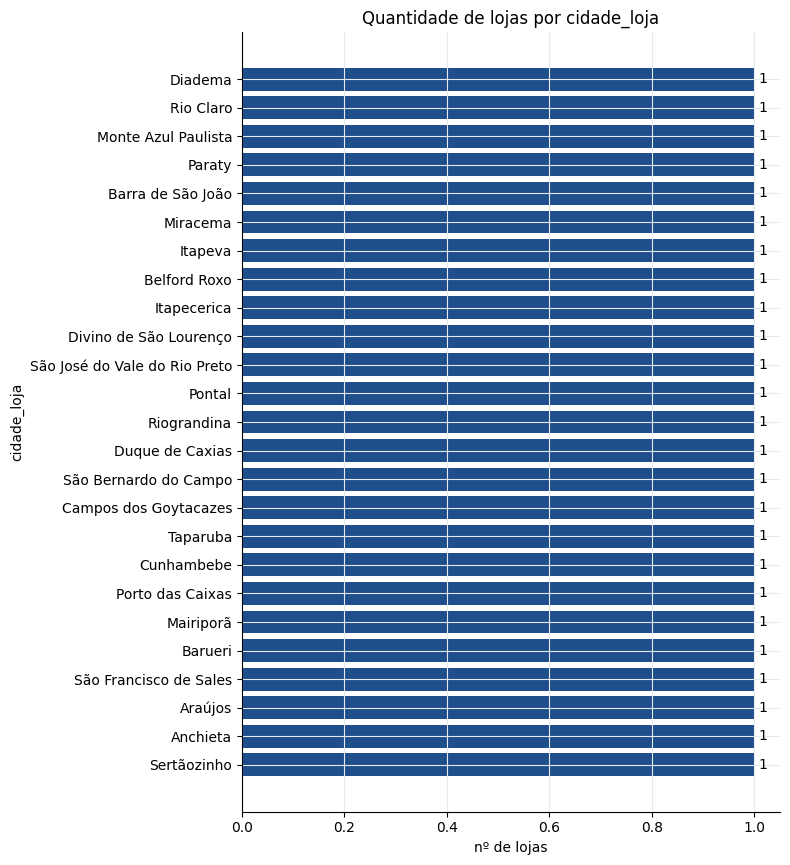

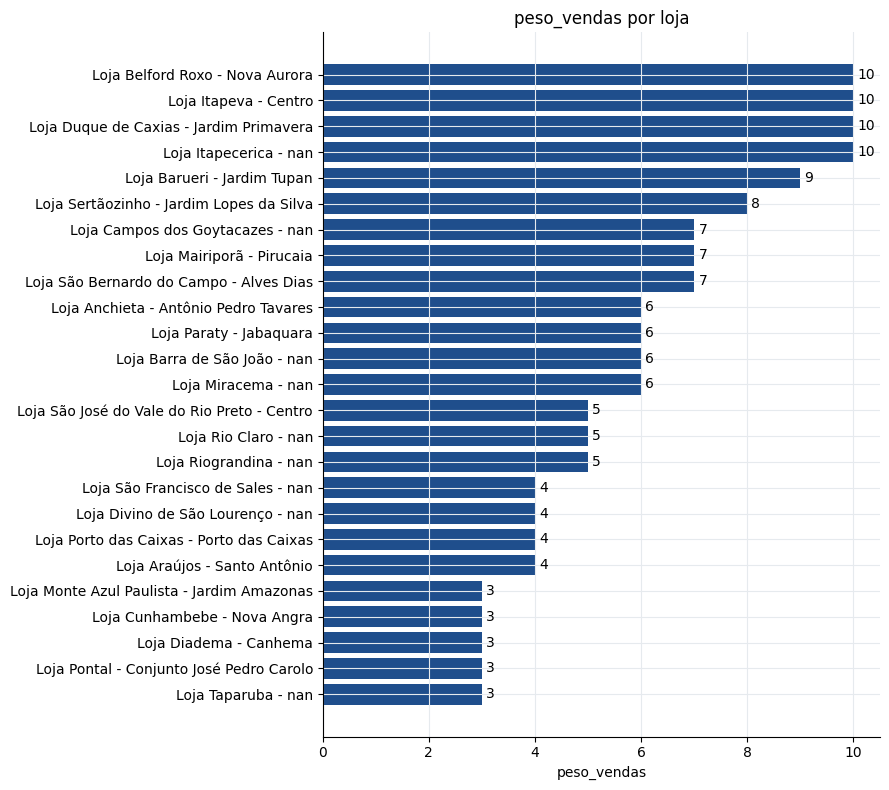

Resumo por estado:


estado_loja,qtd_lojas,qtd_cidades,peso_vendas_min,peso_vendas_medio,peso_vendas_max
RJ,11,11,3,6.09,10
SP,8,8,3,6.25,10
MG,4,4,3,5.25,10
ES,2,2,4,5.0,6


In [0]:
print(f"Total de lojas no cadastro: {n}")
for col in ["estado_loja", "cidade_loja"]:
    grafico_barras(df, col)

# peso_vendas de cada loja, pelo nome (o valor aparece na ponta da barra)
pl = lojas.sort_values("peso_vendas")
fig, ax = plt.subplots(figsize=(9, max(4, 0.32 * len(pl))))
ax.bar_label(ax.barh(pl.nome_loja, pl.peso_vendas, color=AZUL), padding=3)
ax.set(title="peso_vendas por loja", xlabel="peso_vendas")
plt.tight_layout(); plt.show()

print("Resumo por estado:")
display(lojas.groupby("estado_loja")
             .agg(qtd_lojas=("id_loja", "size"), qtd_cidades=("cidade_loja", "nunique"),
                  peso_vendas_min=("peso_vendas", "min"), peso_vendas_medio=("peso_vendas", "mean"),
                  peso_vendas_max=("peso_vendas", "max"))
             .round(2).reset_index().sort_values("qtd_lojas", ascending=False))

## 4. LOJAS × VENDAS: INTEGRIDADE E PESO_VENDAS

Lojas cadastradas sem nenhuma venda: nenhuma
id_loja nas vendas sem cadastro (sem nome): [11, 15, 29, 7]


id_loja,nome_loja,cidade_loja,estado_loja,peso_vendas,bronze_ingested_at,bronze_source_file,ano,mes,_hash_registro,silver_processed_at,receita,transacoes,primeira_venda,ultima_venda,ticket_medio,pct_receita
2,Loja Duque de Caxias - Jardim Primavera,Duque de Caxias,RJ,10,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,76bd4de85267acdb49c1e6710ef8e7128ca4cda32848ff4774e75cc28c363218,2026-10-07T18:40:07.687Z,8481622.96,23128,2024-01-01T05:43:49.000Z,2026-08-31T23:51:19.000Z,366.73,7.06
9,Loja Belford Roxo - Nova Aurora,Belford Roxo,RJ,10,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,2fc8d9f8d029e7c110d54a9294239067ba1e7aa6dc55c5bd56c92f5ae98747b5,2026-10-07T18:40:07.687Z,8066169.85,22059,2024-01-01T02:01:51.000Z,2026-08-31T22:50:17.000Z,365.66,6.71
10,Loja Itapecerica - nan,Itapecerica,MG,10,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,80df3901be6a2a486a34bb9794dece79e664ae23e6072c74727c716ae17fa6af,2026-10-07T18:40:07.687Z,8046143.08,22212,2024-01-01T01:17:21.000Z,2026-08-31T23:32:39.000Z,362.24,6.7
6,Loja Itapeva - Centro,Itapeva,SP,10,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,e8d8c9ad412b533d7da3b577c5ad2b064eeb5da311094dbe17035a30fd55c974,2026-10-07T18:40:07.687Z,7937764.32,21982,2024-01-01T07:17:13.000Z,2026-08-31T22:04:03.000Z,361.1,6.61
5,Loja Barueri - Jardim Tupan,Barueri,SP,9,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,29bd7d97f7a234eedd30a85dad27af04897140d4d3ad28e1c52705cf8918b3a5,2026-10-07T18:40:07.687Z,7493144.18,20399,2024-01-01T06:50:36.000Z,2026-08-31T22:53:58.000Z,367.33,6.24
1,Loja São Bernardo do Campo - Alves Dias,São Bernardo do Campo,SP,7,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,369b0767629109babea63d61c0b078beca70a2cd167fcdbdfd6fe73f552eafb9,2026-10-07T18:40:07.687Z,7259212.85,19875,2024-01-01T07:40:50.000Z,2026-08-31T23:43:57.000Z,365.24,6.04
3,Loja Sertãozinho - Jardim Lopes da Silva,Sertãozinho,SP,8,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,e8aafff6534bac0787091e789d49e622ceb6fed012c267bd35e0ea58e280f226,2026-10-07T18:40:07.687Z,6721462.89,18641,2024-01-01T03:09:19.000Z,2026-08-31T23:50:42.000Z,360.57,5.59
4,Loja Campos dos Goytacazes - nan,Campos dos Goytacazes,RJ,7,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,2c1f8893b287736be0393dd0ebe5d9834355089f9ffb460bdf46e874c7493734,2026-10-07T18:40:07.687Z,5958325.77,16339,2024-01-01T01:00:17.000Z,2026-08-31T22:16:14.000Z,364.67,4.96
8,Loja Mairiporã - Pirucaia,Mairiporã,SP,7,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,7b7a03fc771ceba0b20f2d794e6a88c9b7cb79e1abeb505a603a6c917303739e,2026-10-07T18:40:07.687Z,5813330.25,15920,2024-01-01T01:58:12.000Z,2026-08-31T21:45:59.000Z,365.16,4.84
25,Loja Anchieta - Antônio Pedro Tavares,Anchieta,ES,6,2026-09-29T20:01:14.922Z,abfss://raw@internshipdatalake.dfs.core.windows.net/batch-data/physical_lojas.csv,2026,10,f1397fa1a1af628be38802fe242275a47b288b371a197aa66b30ea76b5bfbf71,2026-10-07T18:40:07.687Z,4697386.11,12741,2024-01-01T09:29:43.000Z,2026-08-31T23:37:07.000Z,368.68,3.91


Lojas com histórico mais curto que a rede (01/01/2024 a 31/08/2026):
nenhuma: todas as lojas vendem no período inteiro
Spearman peso_vendas × receita: 0.99
Spearman peso_vendas × ticket médio: -0.6


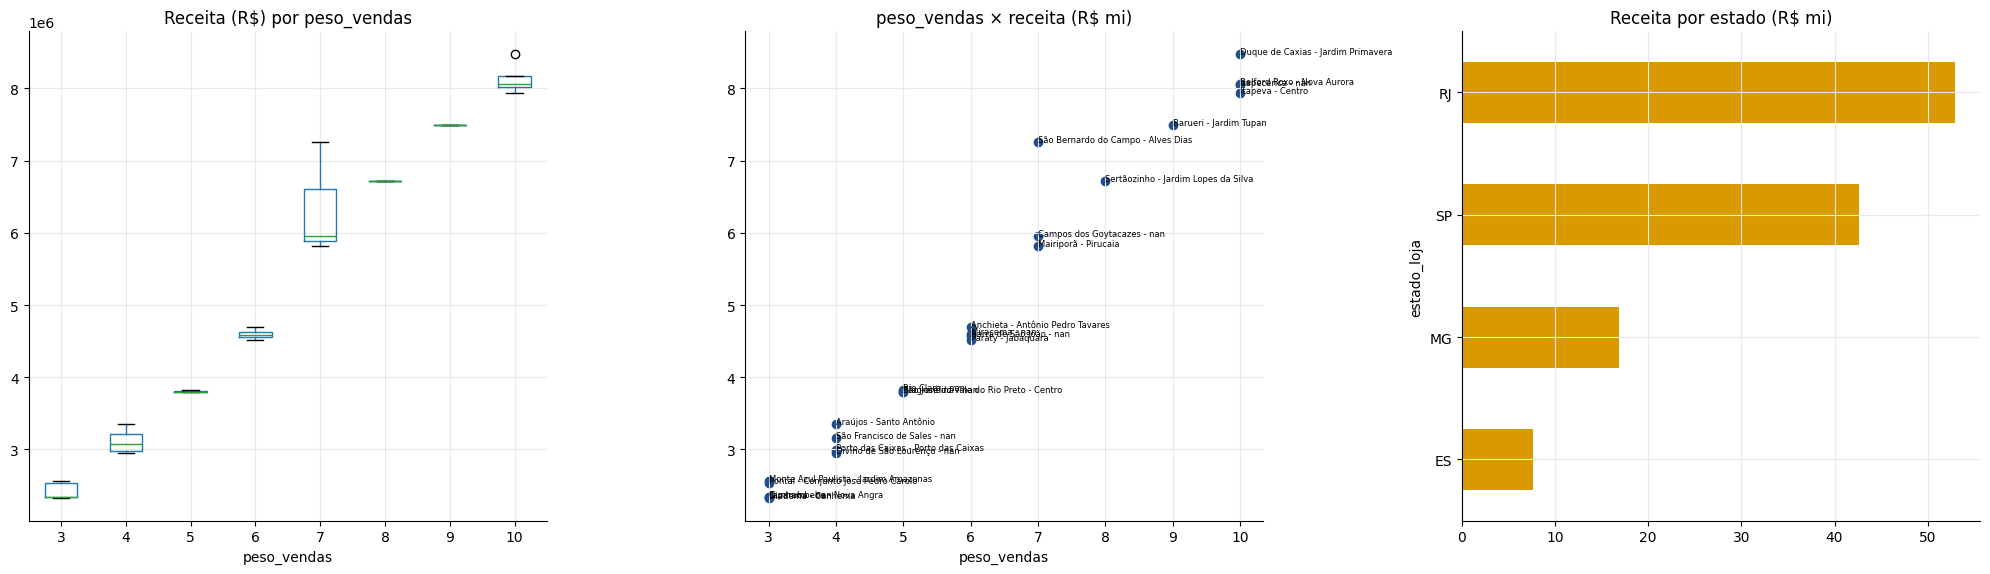

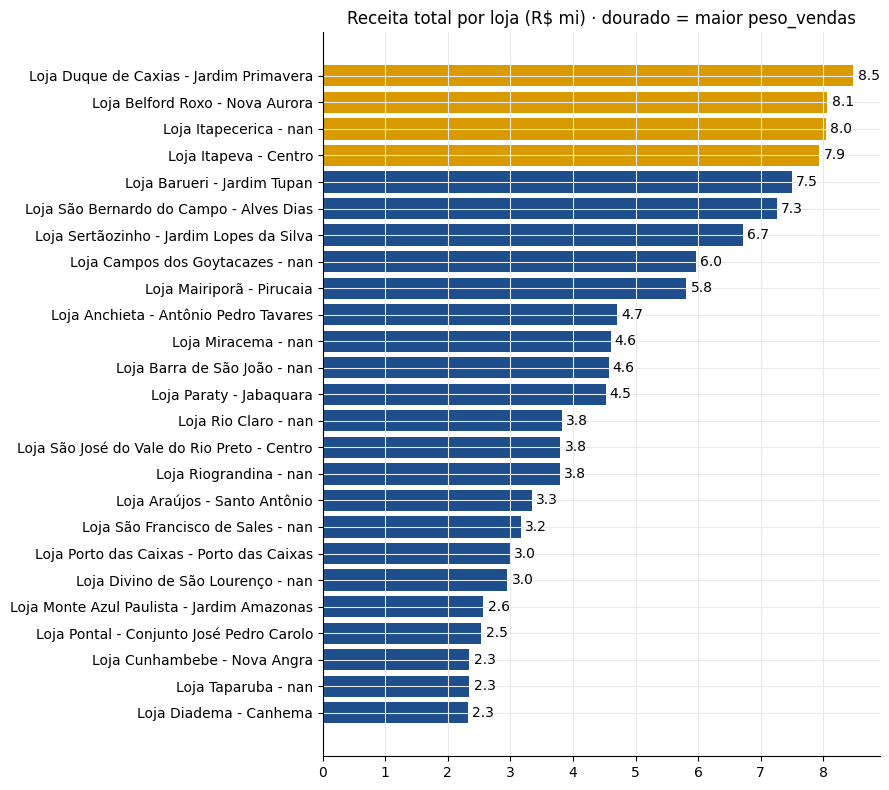

In [0]:
vendas = ler("physical_vendas_caixa").withColumn("ts", F.to_timestamp("dt_venda"))
por_loja = vendas.groupBy("id_loja").agg(F.sum(F.col("valor_total_venda").cast("double")).alias("receita"),
                                         F.count("*").alias("transacoes"),
                                         F.min("ts").alias("primeira_venda"), F.max("ts").alias("ultima_venda"))

print("Lojas cadastradas sem nenhuma venda:", [r.nome_loja for r in df.join(por_loja, "id_loja", "left_anti").collect()] or "nenhuma")
# Estas não estão no cadastro, então não têm nome: só o id existe nas vendas
print("id_loja nas vendas sem cadastro (sem nome):", [r.id_loja for r in por_loja.join(df, "id_loja", "left_anti").collect()] or "nenhum")

lv = df.join(por_loja, "id_loja", "left").toPandas()
lv["peso_vendas"] = pd.to_numeric(lv.peso_vendas)
lv["ticket_medio"] = lv.receita / lv.transacoes
lv["pct_receita"] = 100 * lv.receita / lv.receita.sum()
display(lv.drop(columns="cnpj").sort_values("receita", ascending=False).round(2))

# Lojas que abriram depois ou pararam antes da rede têm série mais curta no modelo
ini, fim = lv.primeira_venda.min(), lv.ultima_venda.max()
curtas = lv[(lv.primeira_venda - ini > pd.Timedelta(days=31)) | (fim - lv.ultima_venda > pd.Timedelta(days=31))]
print(f"Lojas com histórico mais curto que a rede ({ini:%d/%m/%Y} a {fim:%d/%m/%Y}):")
if curtas.empty:
    print("nenhuma: todas as lojas vendem no período inteiro")
else:
    display(curtas[["id_loja", "nome_loja", "primeira_venda", "ultima_venda"]])

print("Spearman peso_vendas × receita:", round(lv.peso_vendas.corr(lv.receita, method="spearman"), 2))
print("Spearman peso_vendas × ticket médio:", round(lv.peso_vendas.corr(lv.ticket_medio, method="spearman"), 2))

fig, ax = plt.subplots(1, 3, figsize=(20, 6))
lv.boxplot(column="receita", by="peso_vendas", ax=ax[0]); ax[0].set_title("Receita (R$) por peso_vendas")
ax[1].scatter(lv.peso_vendas, lv.receita / 1e6, color=AZUL); ax[1].set(title="peso_vendas × receita (R$ mi)", xlabel="peso_vendas")
for _, r in lv.iterrows():
    ax[1].annotate(str(r.nome_loja).removeprefix("Loja "), (r.peso_vendas, r.receita / 1e6), fontsize=6)
(lv.groupby("estado_loja").receita.sum() / 1e6).sort_values().plot.barh(ax=ax[2], color=OURO, title="Receita por estado (R$ mi)")
fig.suptitle(""); plt.tight_layout(); plt.show()

top = lv.sort_values("receita")
plt.figure(figsize=(9, 8))
plt.bar_label(plt.barh(top.nome_loja, top.receita / 1e6, color=[OURO if p == top.peso_vendas.max() else AZUL for p in top.peso_vendas]),
              fmt="%.1f", padding=3)
plt.title("Receita total por loja (R$ mi) · dourado = maior peso_vendas"); plt.tight_layout(); plt.show()

## 5. RESUMO DOS ACHADOS

In [0]:
achados = {
    "lojas cadastradas": n,
    "problemas no cadastro (soma das checagens)": sum(checagens.values()),
    "estados / cidades": f"{lojas.estado_loja.nunique()} / {lojas.cidade_loja.nunique()}",
    "lojas sem venda": int(lv.receita.isna().sum()),
    "lojas com histórico curto": len(curtas),
    "Spearman peso_vendas × receita": round(lv.peso_vendas.corr(lv.receita, method="spearman"), 2),
    "maior loja / menor loja (receita)": f"{lv.receita.max() / lv.receita.min():.1f}×",
}
display(pd.DataFrame(achados.items(), columns=["achado", "valor"]).astype(str))


achado,valor
lojas cadastradas,25
problemas no cadastro (soma das checagens),5
estados / cidades,4 / 25
lojas sem venda,0
lojas com histórico curto,0
Spearman peso_vendas × receita,0.99
maior loja / menor loja (receita),3.7×


## 6. CONCLUSÕES E DECISÕES PARA A ENGENHARIA DE FEATURES

**1. Cadastro** (seções 1 e 2)
- Problemas encontrados (ids, CNPJ, nomes, textos): 5 Lojas faltantes (7, 11, 14, 15 e 29) e CNPJ perde os zeros à esquerda
- Tratamento proposto: 1) Verificar se os dados das lojas dos IDS passados não foram corrompidos e validar na planilha inicial do caminho na raw; 2)Alterar tipo numérico para não perder os zeros à esquerda e verificar se essa não alteração que trouxe a perda das 5 lojas para a camada Silver.

**2. Distribuição** (seção 3)
- Estados e cidades com mais lojas: a rede está em 4 estados, com RJ concentrando a maior parte (11 lojas), seguido de SP (8), MG (4) e ES (2). Cada loja fica em uma cidade diferente (25 lojas em 25 cidades), então não há cidade com mais de uma loja.
- Faixa do peso_vendas: - Faixa do peso_vendas: vai de 3 a 10. O valor mais comum é 3 (5 lojas); os pesos 4, 6 e 10 têm 4 lojas cada, 5 e 7 têm 3 cada, e 8 e 9 têm 1 loja cada. O peso médio é maior em SP (6,25) e RJ (6,09) e menor em MG (5,25) e ES (5,0).
- Observação: esses números são da Silver, que tem 25 lojas. As lojas 7 (SP), 11 (MG), 15 (ES) e 29 (RJ) ficaram de fora por causa do CNPJ sem o zero à esquerda. Com elas, a rede passa a ter 29 lojas: RJ 12, SP 9, MG 5 e ES 3.

**3. Lojas × vendas** (seção 4)
- Lojas nas vendas sem cadastro: 4 lojas (7 – Caçapava, 11 – Bom Sucesso, 15 – Itarana e 29 – Campos Elyseos), que somam 12,4% da receita da rede. Elas existem no cadastro de origem, mas foram descartadas na Silver porque o CNPJ perdeu o zero à esquerda (os CNPJs são válidos). 
- Lojas sem venda: nenhuma. Todas as lojas do cadastro vendem no período inteiro (01/01/2024 a 31/08/2026), então todas as séries têm o mesmo tamanho. O id 14 não existe nem no cadastro nem nas vendas, é só uma lacuna na numeração.
- O peso_vendas acompanha a receita? Sim, quase perfeitamente: Spearman 0,99. A receita média por loja sobe a cada nível de peso, de R$ 2,5 mi (peso 3) a R$ 8,1 mi (peso 10). O ticket médio vai no sentido contrário (Spearman −0,60): lojas de peso maior vendem mais pelo volume de transações, não por venda mais cara. → **usar para agrupar as lojas pequenas**: o quartil de menor receita (Q1) são exatamente as lojas de peso 3 e 4, então o grupo pode ser definido por `peso_vendas ≤ 4`. 

**4. Features candidatas** 
- `peso_vendas`, `estado_loja` (one-hot ou média da receita do estado), `grupo_porte` (Q1–Q4 da receita)